In [1]:
import pandas as pd
import numpy as np

import yfinance as yf

import matplotlib.pyplot as plt
import seaborn as sns

from datetime import date, timedelta

In [2]:
start_date = date(2002, 12, 31)
end_date = date.today()

In [6]:
# Leveraging yfinance to download LQD ETF data from Yahoo Finance
lqd_series = yf.download(
    ['LQD'], 
    start=start_date.strftime('%Y-%m-%d'), 
    end=end_date.strftime('%Y-%m-%d'), 
    auto_adjust=True
)['Close'] # Adjust if necessary to get more than the 'Close' prices

if isinstance(lqd_series.columns, pd.MultiIndex):
    lqd_series.columns = lqd_series.columns.get_level_values(0).rename(None)

[*********************100%***********************]  1 of 1 completed


## LQD: iShares Investment-Grade Corporate Bond
### Trading Strategies

1) **Moving Average Trend Strategy**
General Idea: When a medium term moving average (e.g., 30-day) exceeds a long-term moving average (e.g., 100-day) we initiate a long position and vice versa (i.e., short-position) in the opposite case. The assumption is that trends tend to persist whether up / down and thus “riding the wave” is advantageous for a simple strategy.
2) **Relative Strength (RSI) Mean Reversion Strategy**
General Idea: We assume there is a “fair-value” price for a given stock / ETF and assume that short-term price moves will quickly revert back to this “fair-value”. Using RSI we’ll denote overbought / oversold levels as points in which we either sell / buy the underlying asset.
3) **Lagged Short-Term Momentum Strategy** 
General idea: Similar in concept to the moving average trend strategy, albeit much shorter duration with the idea hinging on continuing short-momentum in an underlying asset (i.e., if we see three days of higher highs we initiate a long position, and vice versa or shorts).
4) **Risk Pool Strategy**
General Idea: This mirrors a multi-strat fund approach where our 1-3 strategies are treated as “funds” which we dynamically allocate across to maximize our overall PnL.


In [50]:
def moving_avg_signal(series, fast_window=20, slow_window=50) -> pd.DataFrame:
    """
    Function to compute the moving average signal for a given series.
    
    Parameters:
    series (pd.Series): The input time series data.
    fast_window (int): The window size for the fast moving average.
    slow_window (int): The window size for the slow moving average.
    
    Returns:
    pd.Series: A series containing the moving average boolean signal. 
    A value of 1 indicates long the asset, -1 indicates short the asset , and 0 indicates no action.
    """
    fast = series.rolling(window=fast_window).mean()
    slow = series.rolling(window=slow_window).mean()

    col_select = series.columns[0]

    series['signal'] = (fast - slow)[col_select].apply(lambda x: 1 if x > 0 else (-1 if x < 0 else 0))
    return series.copy()

In [ ]:
def pnl_creation(series) -> pd.DataFrame:
    """
    Function to compute the PnL based on the series and the accompanying position signal.
    
    Parameters:
    series (pd.Series): The input time series data.
    signal (pd.Series): The position signal.
    
    Returns:
    pd.Series: A series containing the PnL values.
    """
    df = series.copy()
    df['pct_chg'] = df[df.columns[0]].pct_change()
    df['pnl'] = df['pct_chg'] * df['signal']

    # Cumulative PnL calculation 
    df['pnl'] = 1 + df['pnl']
    df.iloc[0, df.columns.get_loc('pnl')] = 100
    df['pnl'] = df['pnl'].cumprod()

    # Benchmark buy-hold PnL caculation

    return df

In [70]:
def buy_hold_pnl(series) -> pd.DataFrame:
    """
    Function to compute the buy-hold PnL based on the series.
    
    Parameters:
    series (pd.Series): The input time series data.
    
    Returns:
    pd.Series: A series containing the buy-hold PnL values.
    """
    df = series.copy()
    df['pct_chg'] = df[df.columns[0]].pct_change()
    
    # Cumulative PnL calculation 
    df['pnl'] = 1 + df['pct_chg']
    df.iloc[0, df.columns.get_loc('pnl')] = 100
    df['pnl'] = df['pnl'].cumprod()

    return df

In [91]:
def strategy_statistics(series) -> tuple:
    """
    Function to compute the statistics of the strategy based on the series.
    
    Parameters:
    series (pd.Series): The input time series data.
    
    Returns:
    tuple: A tuple containing the mean and standard deviation of the PnL values.
    """

    log_returns = np.log(series['pnl'] / series['pnl'].shift(1))
    log_returns = log_returns.dropna()  # Drop NaN values resulting from the shift operation
    log_returns = log_returns[log_returns != 0]  # Filter out zero returns to avoid issues with volatility calculation

    annual_vol = log_returns.std() * np.sqrt(252)  # Annualized volatility
    dt = (series.index[-1] - series.index[0]).days
    annual_ret = ( series['pnl'].iloc[-1] / series['pnl'].iloc[0] ) ** (365 / dt) - 1  # Annualized return
    
    return annual_ret, annual_vol, annual_ret / annual_vol  # Sharpe ratio

In [101]:
benchmark = buy_hold_pnl(lqd_series)

### Simulation for Best Moving Average Approach

In [110]:
strategy_combination = []
for fast_window in np.arange(10, 55, 5):
    for slow_window in np.arange(50, 210, 10):
        strategy = pnl_creation(moving_avg_signal(lqd_series, fast_window=fast_window, slow_window=slow_window))
        annual_ret, annual_vol, sharpe_ratio = strategy_statistics(strategy)
        strategy_combination.append((fast_window, slow_window, annual_ret, annual_vol, sharpe_ratio))

In [115]:
pd.DataFrame(
    strategy_combination, 
    columns=['Fast Window', 'Slow Window', 'Annual Return', 'Annual Volatility', 'Sharpe Ratio']
).sort_values(by='Sharpe Ratio', ascending=False)

,Fast Window,Slow Window,Annual Return,Annual Volatility,Sharpe Ratio
5,10,100,0.034207,0.084188,0.406318
16,15,50,0.032514,0.084175,0.386273
3,10,80,0.030301,0.084145,0.360110
32,20,50,0.029025,0.084183,0.344785
2,10,70,0.028764,0.084114,0.341965
...,...,...,...,...,...
137,50,140,-0.006307,0.084162,-0.074936
136,50,130,-0.007305,0.084181,-0.086773
56,25,130,-0.007365,0.084444,-0.087216
69,30,100,-0.008252,0.084402,-0.097776


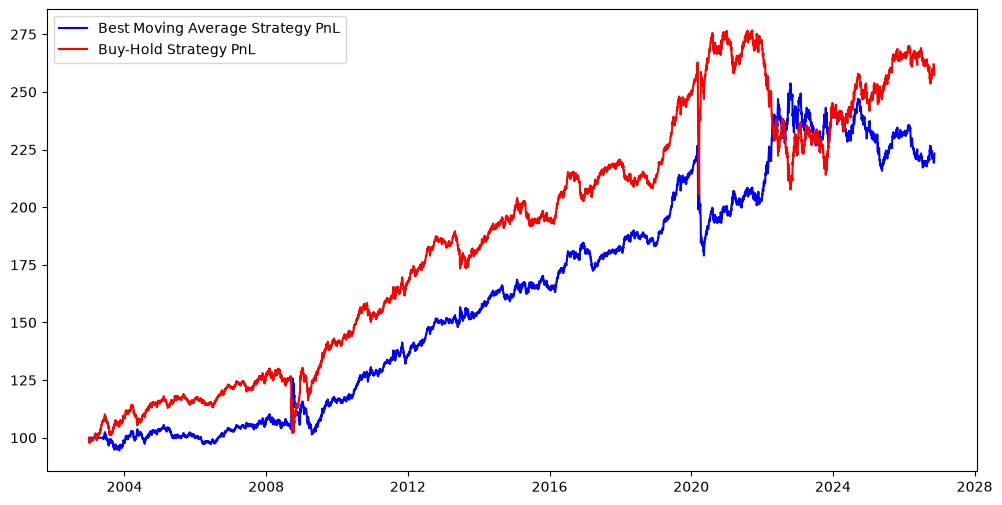

In [ ]:
best_strategy =  pnl_creation(moving_avg_signal(lqd_series, fast_window=10, slow_window=100))

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(best_strategy['pnl'], label='Best Moving Average Strategy PnL', color='blue')
ax.plot(benchmark['pnl'], label='Buy-Hold Strategy PnL', color='red')
ax.legend()

plt.show()